# UniRef50 homolog count

## 1. Data acquisition

ClinVar GRCh38 June 6, 2026 and the official AlphaMissense hg38 score release are fixed below. The homology input is the complete released per-hit search measurement against UniRef50 release 2026_01. This notebook freshly counts distinct hits and performs the clinical analysis; it does not claim to rerun the 268 GB database search.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
SOURCES = [{'id': 'am_hg38',
  'path': 'inputs/raw/AlphaMissense_hg38.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz',
  'sha256': '0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475',
  'bytes': 642961469},
 {'id': 'clinvar',
  'path': 'clinvar_20260606.vcf.gz',
  'url': 'https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260606.vcf.gz',
  'sha256': 'c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0e0bfe689fbe96b8726',
  'bytes': 196569024},
 {'id': 'uniref_hits',
  'path': 'am-original-uniref-hits-20260606.m8.gz',
  'url': 'https://github.com/yashaektefaie/SPECTRAagent/releases/download/primary-reproduction-2026-11-08/am-original-uniref-hits-20260606.m8.gz',
  'sha256': '265a1872bed445cf32c38798738bb988fd044dafdc4d5fb6fb5fb248fdca7e01',
  'bytes': 183094126}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


,path,url,sha256,bytes
0,AlphaMissense_hg38.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_hg38.tsv.gz,0516cfd71c0767ac8f9c469252d429000e94e02c008b6e3a46d4b4646fcd3475,642961469
1,clinvar_20260606.vcf.gz,https://ftp.ncbi.nlm.nih.gov/pub/clinvar/vcf_GRCh38/archive_2.0/2026/clinvar_20260606.vcf.gz,c5bb136e1ac476d390d8110905e8224126ce7d43d5eae0e0bfe689fbe96b8726,196569024
2,am-original-uniref-hits-20260606.m8.gz,https://github.com/yashaektefaie/SPECTRAagent/releases/download/primary-reproduction-2026-11-08/...,265a1872bed445cf32c38798738bb988fd044dafdc4d5fb6fb5fb248fdca7e01,183094126


The search measurement uses MMseqs2 against UniRef50 2026_01 with E-value <0.001 and coverage threshold 0.5 with coverage mode 0. The full database can be acquired from `https://ftp.uniprot.org/pub/databases/uniprot/previous_major_releases/release-2026_01/uniref/uniref2026_01.tar.gz` (MD5 `4eb0172248fa0f8f96e86aedc57e485c`). The defining command is `mmseqs easy-search query.fasta uniref50DB hits.m8 tmp --threads 16 -s 5.7 --max-seqs 10000 -e 1e-3 -c 0.5 --cov-mode 0 --format-output query,target,fident,qcov,evalue`. The source hit table is treated as a fixed measurement, analogous to the released target predictions.


## 2. Raw processing

Parse single-nucleotide missense ClinVar alleles, require at least one review star and an unambiguous pathogenic/likely-pathogenic or benign/likely-benign class, and join exact genomic keys to the released scores. Each matching AlphaMissense transcript row is retained. Negative BLOSUM62 uses the same amino-acid substitution.


In [3]:
STARS={'practice_guideline':4,'reviewed_by_expert_panel':3,'criteria_provided,_multiple_submitters,_no_conflicts':2,'criteria_provided,_single_submitter':1,'criteria_provided,_conflicting_classifications':1}
PATHOGENIC={'Pathogenic','Likely_pathogenic','Pathogenic/Likely_pathogenic'};BENIGN={'Benign','Likely_benign','Benign/Likely_benign'}
clin={};qc=Counter();bases=set('ACGT')
with gzip.open(RAW/'clinvar_20260606.vcf.gz','rt') as f:
    for line in f:
        if line.startswith('#'):continue
        p=line.rstrip().split('\t');qc['ClinVar rows']+=1;chrom,pos,vid,ref,alt=p[:5]
        if len(ref)!=1 or len(alt)!=1 or ref not in bases or alt not in bases:continue
        info=dict(x.split('=',1) for x in p[7].split(';') if '=' in x)
        if 'missense_variant' not in info.get('MC',''):continue
        sig=info.get('CLNSIG','');stars=STARS.get(info.get('CLNREVSTAT',''),0)
        if sig not in PATHOGENIC|BENIGN or stars<1:continue
        clin[('chr'+chrom,pos,ref,alt)]={'label':int(sig in PATHOGENIC),'stars':stars,'gene':info.get('GENEINFO','').split(':')[0],'variation_id':vid}
rows=[];B62=substitution_matrices.load('BLOSUM62');AA=set('ACDEFGHIKLMNPQRSTVWY')
with gzip.open(RAW/'AlphaMissense_hg38.tsv.gz','rt') as f:
    for line in f:
        if line.startswith('#'):continue
        p=line.rstrip().split('\t');qc['AlphaMissense rows']+=1;key=tuple(p[:4]);hit=clin.get(key)
        if hit is None:continue
        pv=p[7]
        if pv[0] not in AA or pv[-1] not in AA:continue
        rows.append({**hit,'key':':'.join(key),'uniprot':p[5],'protein_variant':pv,'am':float(p[8]),'blosum':-float(B62[pv[0],pv[-1]])})
df=pd.DataFrame(rows);qc['Matched transcript rows']=len(df);qc['Matched genomic alleles']=df.key.nunique();qc['Proteins']=df.uniprot.nunique()
display(pd.Series(qc,name='count').to_frame());display(df.drop(columns=['am','blosum']).head())


,count
ClinVar rows,4435099
AlphaMissense rows,71697556
Matched transcript rows,194408
Matched genomic alleles,191664
Proteins,14874


,label,stars,gene,variation_id,key,uniprot,protein_variant
0,0,1,OR4F5,2205837,chr1:69134:A:G,Q8NH21,E15G
1,0,1,SAMD11,1648427,chr1:925969:C:T,Q96NU1,P10S
2,0,1,SAMD11,1164676,chr1:930165:G:A,Q96NU1,R28Q
3,0,2,SAMD11,1170208,chr1:930204:G:A,Q96NU1,R41Q
4,0,2,SAMD11,789256,chr1:930248:G:A,Q96NU1,G56S


## 3. Axis and levels

Count distinct UniRef50 targets per protein, remove proteins with no search measurement, and form protein-balanced deciles of log10(1+count).


In [4]:
homologs=defaultdict(set)
with gzip.open(RAW/'am-original-uniref-hits-20260606.m8.gz','rt') as f:
    for line in f:
        q,t=line.split('\t',2)[:2];homologs[q].add(t)
depth={p:len(targets) for p,targets in homologs.items()}
df['depth']=df.uniprot.map(depth).fillna(0);print('Rows without search support:',int((df.depth==0).sum()));df=df[df.depth>0].copy();df['feature']=np.log10(1+df.depth);CLUSTER='uniprot'

feature_by_cluster=df.groupby(CLUSTER).feature.first();edges=np.quantile(feature_by_cluster,np.linspace(0,1,11));edges[0]-=1e-9;edges[-1]+=1e-9
df['level']=np.clip(np.searchsorted(edges,df.feature,side='right')-1,0,9)
display(pd.DataFrame({'boundary':range(11),'feature_value':edges}));display(df.groupby('level').feature.agg(['size','min','median','max']))


Rows without search support: 29


,boundary,feature_value
0,0,0.301030
1,1,1.698970
2,2,1.963788
3,3,2.149219
4,4,2.311754
5,5,2.471292
6,6,2.659916
7,7,2.877371
8,8,3.151982
9,9,3.508664


,size,min,median,max
level,,,,
0,19153,0.301030,1.531479,1.690196
1,18474,1.698970,1.857332,1.959041
2,15461,1.963788,2.053078,2.146128
3,16307,2.149219,2.222716,2.309630
4,21935,2.311754,2.392697,2.469822
5,22621,2.471292,2.563481,2.658965
6,23955,2.659916,2.769377,2.876795
7,19188,2.877371,3.006466,3.151676
8,24741,3.151982,3.298635,3.508530


## 4. Released model results and reference

Evaluate released AlphaMissense pathogenicity and negative BLOSUM62 on identical rows. No target training or fine-tuning occurs. Labels are clinical assertions, so the estimate describes this curated cohort rather than a population diagnostic-use setting.


In [5]:
display(df[['key','uniprot','gene','label','am','blosum','level']].head())


,key,uniprot,gene,label,am,blosum,level
0,chr1:69134:A:G,Q8NH21,OR4F5,0,0.0854,2.0,9
1,chr1:925969:C:T,Q96NU1,SAMD11,0,0.9673,1.0,1
2,chr1:930165:G:A,Q96NU1,SAMD11,0,0.6624,-1.0,1
3,chr1:930204:G:A,Q96NU1,SAMD11,0,0.0866,-1.0,1
4,chr1:930248:G:A,Q96NU1,SAMD11,0,0.1004,-0.0,1


## 5. Curves and controls

AUROC intervals use 500 bootstrap resamples of the feature-defining protein/gene units. The target and reference share the same resamples. Show review-quality strata, label prevalence, and the constraint diagnostic where available. The ten-point rank association describes the curve; it is not a variant-level inferential test.


,level,score,variants,clusters,pathogenic_fraction,feature_median,AUROC,ci_low,ci_high
0,0,am,19153,1450,0.108286,1.531479,0.968143,0.953763,0.979242
1,0,blosum,19153,1450,0.108286,1.531479,0.664363,0.642933,0.686286
2,1,am,18474,1510,0.133918,1.857332,0.962092,0.949301,0.972824
3,1,blosum,18474,1510,0.133918,1.857332,0.686976,0.671845,0.704662
4,2,am,15461,1493,0.171205,2.053078,0.962481,0.955001,0.970678
5,2,blosum,15461,1493,0.171205,2.053078,0.715883,0.689586,0.735214
6,3,am,16307,1471,0.193291,2.222716,0.959470,0.950134,0.967347
7,3,blosum,16307,1471,0.193291,2.222716,0.683652,0.666696,0.699246
8,4,am,21935,1504,0.246182,2.392697,0.960057,0.951431,0.967082
9,4,blosum,21935,1504,0.246182,2.392697,0.687583,0.667514,0.703958


,score,high_minus_low,ci_low,ci_high,level_Spearman,level_pvalue
0,am,-0.000427,-0.012798,0.014870,-0.212121,0.556306
1,blosum,0.044395,0.019499,0.068815,0.284848,0.425038


,level,variants,pathogenic_fraction,genes,proteins,feature_median
0,0,19153,0.108286,1460,1450,1.531479
1,1,18474,0.133918,1526,1510,1.857332
2,2,15461,0.171205,1513,1493,2.053078
3,3,16307,0.193291,1471,1471,2.222716
4,4,21935,0.246182,1533,1504,2.392697
5,5,22621,0.305557,1506,1489,2.563481
6,6,23955,0.463870,1494,1485,2.769377
7,7,19188,0.420211,1510,1490,3.006466
8,8,24741,0.434057,1475,1487,3.298635
9,9,12544,0.431840,1445,1487,3.690462


,review_group,level,variants,AM_AUROC,reference_AUROC
0,1 star,0,14173,0.964467,0.668865
1,1 star,1,13411,0.964694,0.691805
2,1 star,2,10883,0.967244,0.723002
3,1 star,3,11455,0.959396,0.694988
4,1 star,4,14553,0.961680,0.695066
5,1 star,5,15432,0.955247,0.688725
6,1 star,6,15371,0.967609,0.740266
7,1 star,7,11986,0.965640,0.712050
8,1 star,8,16608,0.960820,0.686155
9,1 star,9,8625,0.973174,0.723464


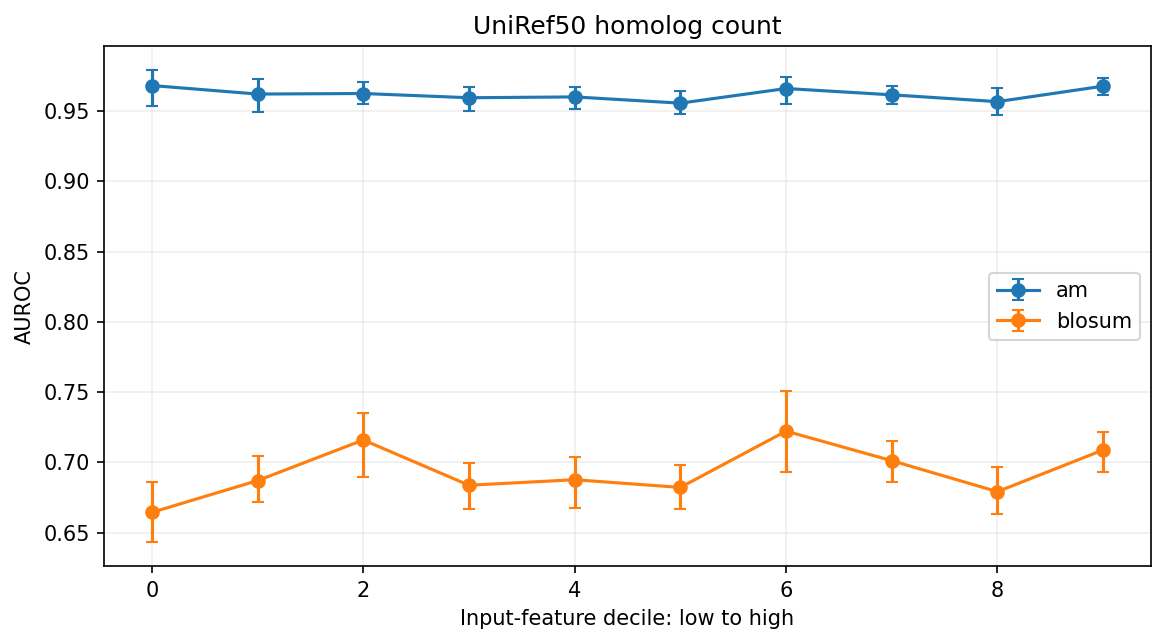

In [6]:
AXIS='UniRef50 homolog count'
SEED=0

rng=np.random.default_rng(SEED);curves=[];draws={};B=500
for level,d in df.groupby('level'):
    clusters=sorted(d[CLUSTER].unique());index={x:i for i,x in enumerate(clusters)};arrays={}
    for score in ['am','blosum']:
        s=d[score].to_numpy();ix=np.argsort(s,kind='stable');s=s[ix];y=d.label.to_numpy()[ix];gi=d[CLUSTER].map(index).to_numpy()[ix];starts=np.r_[0,np.flatnonzero(s[1:]!=s[:-1])+1];arrays[score]=(y,gi,starts)
    b={score:[] for score in arrays}
    for _ in range(B):
        weights=rng.multinomial(len(clusters),np.full(len(clusters),1/len(clusters)))
        for score,(y,gi,starts) in arrays.items():
            w=weights[gi];pos=np.add.reduceat(w*y,starts);neg=np.add.reduceat(w*(1-y),starts);den=pos.sum()*neg.sum();b[score].append(np.sum(pos*(np.cumsum(neg)-.5*neg))/den if den else np.nan)
    for score,values in b.items():
        lo,hi=np.nanquantile(values,[.025,.975]);curves.append({'level':int(level),'score':score,'variants':len(d),'clusters':len(clusters),'pathogenic_fraction':d.label.mean(),'feature_median':d.feature.median(),'AUROC':roc_auc_score(d.label,d[score]),'ci_low':lo,'ci_high':hi});draws[level,score]=np.array(values)
curves=pd.DataFrame(curves);control=[]
for stars,d in df.groupby(df.stars>=2):
    for level,x in d.groupby('level'):
        if x.label.nunique()==2:control.append({'review_group':'2+ stars' if stars else '1 star','level':level,'variants':len(x),'AM_AUROC':roc_auc_score(x.label,x.am),'reference_AUROC':roc_auc_score(x.label,x.blosum)})
controls=pd.DataFrame(control);composition=df.groupby('level').agg(variants=('label','size'),pathogenic_fraction=('label','mean'),genes=('gene','nunique'),proteins=('uniprot','nunique'),feature_median=('feature','median')).reset_index()
if 'oe_mis' in df:composition=composition.merge(df.groupby('level').oe_mis.median().rename('median_oe_mis'),on='level')
contrast=[]
for score in ['am','blosum']:
    d=curves[curves.score==score].sort_values('level');v=draws[int(d.level.iloc[-1]),score]-draws[int(d.level.iloc[0]),score];lo,hi=np.nanquantile(v,[.025,.975]);rho,p=spearmanr(d.feature_median,d.AUROC);contrast.append({'score':score,'high_minus_low':d.AUROC.iloc[-1]-d.AUROC.iloc[0],'ci_low':lo,'ci_high':hi,'level_Spearman':rho,'level_pvalue':p})
contrast=pd.DataFrame(contrast);display(curves);display(contrast);display(composition);display(controls)
fig,ax=plt.subplots(figsize=(9,4.5))
for score,d in curves.groupby('score'):
    y=d.AUROC.to_numpy();ax.errorbar(d.level,y,yerr=np.maximum(0,np.array([y-d.ci_low,d.ci_high-y])),marker='o',capsize=3,label=score)
ax.set(xlabel='Input-feature decile: low to high',ylabel='AUROC',title=AXIS);ax.legend();ax.grid(alpha=.2);show_figure(fig);plt.close(fig)


## 6. Result and decision

The proposed support hypothesis predicts better discrimination at higher support. The calculated endpoint contrast and complete curve determine whether that direction is supported.


In [7]:
a=contrast.set_index('score').loc['am']
if a.ci_low>0 and a.level_Spearman>0:decision='Retain the higher-support association on this cohort; evaluate the fixed-reference and composition controls before interpreting model specificity.'
else:decision='Do not retain the proposed lower-support degradation claim: the complete calculated curve and endpoint interval do not jointly support the specified direction.'
print(decision)
for name,table in [('curves',curves),('contrasts',contrast),('composition',composition),('controls',controls)]:table.to_csv(OUTPUT/(name+'.csv'),index=False)
df.to_csv(OUTPUT/'variants.csv.gz',index=False,compression='gzip')
(OUTPUT/'execution.json').write_text(json.dumps({'sources':source_receipts,'decision':decision,'host':platform.node(),'rows':len(df),'bootstrap_replicates':B,'bootstrap_unit':CLUSTER,'outputs':{p.name:sha256_file(p) for p in OUTPUT.glob('*.csv*')}},indent=2)+'\n')


Do not retain the proposed lower-support degradation claim: the complete calculated curve and endpoint interval do not jointly support the specified direction.


1640